# Tugas Praktikum 6: Clustering (Advance)

**Nama:** Fauzan Tamma Harish Kunfaza  
**NRP:** 5054251035

---

## Pengantar

Di praktikum ini saya menerapkan empat algoritma clustering lanjutan pada data pengukuran fisik penguin (Palmer Penguins), yaitu:

1. **Agglomerative Clustering** (hierarchical): menggabungkan titik demi titik dari bawah ke atas.
2. **DBSCAN** (density-based): membentuk cluster dari area yang padat, titik yang terisolasi dianggap noise.
3. **Gaussian Mixture Models / GMM** (model-based): menganggap data berasal dari campuran beberapa distribusi Gaussian.
4. **Spectral Clustering**: mengelompokkan data lewat graf kemiripan antar titik.

Hasil keempatnya dibandingkan dengan tiga cara: **Silhouette Score** (evaluasi internal), **Rand Index** dan **NMI** (evaluasi eksternal terhadap kolom `species`), lalu diuji **kestabilannya** pada subset data 90%.

Kolom `species` hanya dipakai sebagai pembanding saat evaluasi, tidak ikut dalam proses clustering.

## 1. Import Library

Library utama: `pandas` dan `numpy` untuk data, `matplotlib` untuk visualisasi, `scikit-learn` untuk algoritma dan metrik evaluasi, serta `scipy` untuk dendrogram.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.sparse.csgraph import connected_components

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.metrics import (silhouette_score, rand_score,
                             normalized_mutual_info_score, adjusted_rand_score)

pd.set_option("display.width", 120)

## 2. Mengunduh dan Mengimpor Dataset

Dataset dibaca langsung dari link GitHub yang ada di instruksi. Kalau tidak ada koneksi internet, notebook otomatis membaca file lokal `penguins.csv` (file ini harus berada satu folder dengan notebook, atau di-upload ke Colab).

In [2]:
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

try:
    df = pd.read_csv(url)
    print("Dataset dibaca dari link GitHub.")
except Exception as e:
    df = pd.read_csv("penguins.csv")
    print("Link tidak bisa diakses, dataset dibaca dari file lokal penguins.csv.")

df.head()

Dataset dibaca dari link GitHub.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
print("Ukuran dataset (baris, kolom):", df.shape)

Ukuran dataset (baris, kolom): (344, 8)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


Dataset ini berisi **344 baris dan 8 kolom**. Kolom `species`, `island`, dan `sex` bertipe teks, sedangkan `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`, dan `year` bertipe angka. Dari ringkasan `info()` terlihat jumlah nilai non-null tiap kolom tidak sama, jadi ada data kosong yang perlu diperiksa di tahap berikutnya.

## 3. Eksplorasi dan Pembersihan Data

Pertama saya cek jumlah nilai kosong di tiap kolom.

In [5]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Nilai kosong ada di empat kolom ukuran (masing-masing 2 baris) dan kolom `sex` (11 baris). Sesuai instruksi, baris hanya dihapus jika kosong pada **empat fitur numerik** atau pada **`species`**. Kolom `sex` tidak dipakai untuk clustering, jadi baris yang hanya kosong di `sex` tetap dipertahankan.

In [6]:
fitur = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

jumlah_sebelum = len(df)
df_bersih = df.dropna(subset=fitur + ["species"]).reset_index(drop=True)
jumlah_sesudah = len(df_bersih)

print("Jumlah baris sebelum pembersihan :", jumlah_sebelum)
print("Jumlah baris sesudah pembersihan :", jumlah_sesudah)
print("Baris yang dihapus               :", jumlah_sebelum - jumlah_sesudah)
print("Sisa nilai kosong di kolom sex   :", df_bersih["sex"].isna().sum(), "(tidak dihapus karena sex tidak dipakai)")

Jumlah baris sebelum pembersihan : 344
Jumlah baris sesudah pembersihan : 342
Baris yang dihapus               : 2
Sisa nilai kosong di kolom sex   : 9 (tidak dihapus karena sex tidak dipakai)


In [7]:
print("Jumlah data per spesies:")
df_bersih["species"].value_counts()

Jumlah data per spesies:


species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

In [8]:
df_bersih[fitur].describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Dari statistik deskriptif, skala antar kolom beda jauh. `body_mass_g` ada di kisaran ribuan gram (sekitar 2700 sampai 6300), sedangkan `bill_depth_mm` hanya belasan milimeter. Kalau dipakai apa adanya, `body_mass_g` akan mendominasi perhitungan jarak, jadi data perlu distandardisasi.

Berikut scatter plot awal sebelum clustering (belum ada pewarnaan cluster).

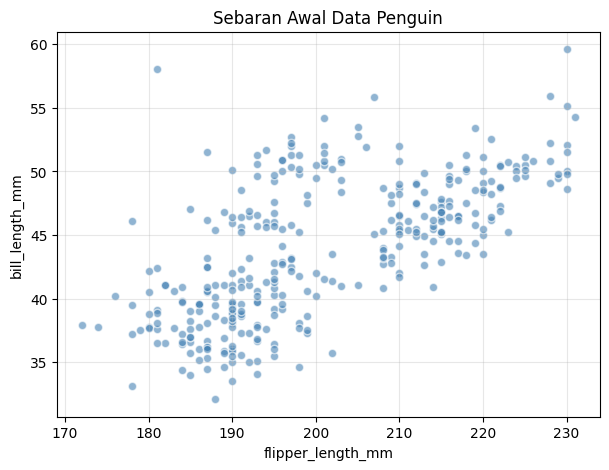

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(df_bersih["flipper_length_mm"], df_bersih["bill_length_mm"],
            color="steelblue", alpha=0.6, edgecolor="white")
plt.title("Sebaran Awal Data Penguin")
plt.xlabel("flipper_length_mm")
plt.ylabel("bill_length_mm")
plt.grid(alpha=0.3)
plt.show()

Dari plot terlihat satu kelompok yang cukup terpisah di kanan atas (sirip panjang), sementara sisanya agak menumpuk di kiri. Jadi kemungkinan ada dua atau tiga kelompok dengan sebagian yang saling tumpang tindih.

## 4. Standardisasi Data

Data dipisah menjadi:
- `X`: empat fitur numerik untuk clustering,
- `y`: kolom `species`, **hanya untuk evaluasi eksternal**.

`X` kemudian distandardisasi dengan z-score, yaitu `(nilai - rata-rata) / standar deviasi`, sehingga setiap kolom punya rata-rata 0 dan standar deviasi 1. Standardisasi penting karena semua algoritma di sini bergantung pada jarak atau kemiripan antar titik, dan satuan antar kolom (milimeter vs gram) berbeda jauh.

In [10]:
X = df_bersih[fitur]
y = df_bersih["species"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)          # array numpy, dipakai oleh semua algoritma

X_scaled_df = pd.DataFrame(X_scaled, columns=fitur)
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
X_scaled_df.head()

Bentuk X: (342, 4) | Bentuk y: (342,)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
3,-1.324737,1.089724,-0.563715,-0.938776
4,-0.847812,1.748985,-0.777373,-0.689020


In [11]:
# Pengecekan: rata-rata harus sekitar 0 dan standar deviasi sekitar 1
X_scaled_df.agg(["mean", "std"]).round(4)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
mean,0.0000,0.0000,-0.0000,0.0000
std,1.0015,1.0015,1.0015,1.0015


## 5. Penerapan Empat Algoritma Clustering

Semua algoritma dijalankan pada `X_scaled`.

### 5.A Agglomerative Clustering

Saya memakai **linkage Ward**. Ward menggabungkan dua cluster yang kenaikan variansi dalam-clusternya paling kecil, sehingga cenderung menghasilkan cluster yang kompak dan ukurannya seimbang. Itu cocok untuk fitur numerik yang sudah distandardisasi. Dendrogram dibuat dengan metode linkage yang sama (`ward`) supaya konsisten dengan model.

In [12]:
agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
label_agglo = agglo.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster (Agglomerative, Ward):")
pd.Series(label_agglo).value_counts().sort_index()

Jumlah anggota tiap cluster (Agglomerative, Ward):


0    162
1    123
2     57
Name: count, dtype: int64

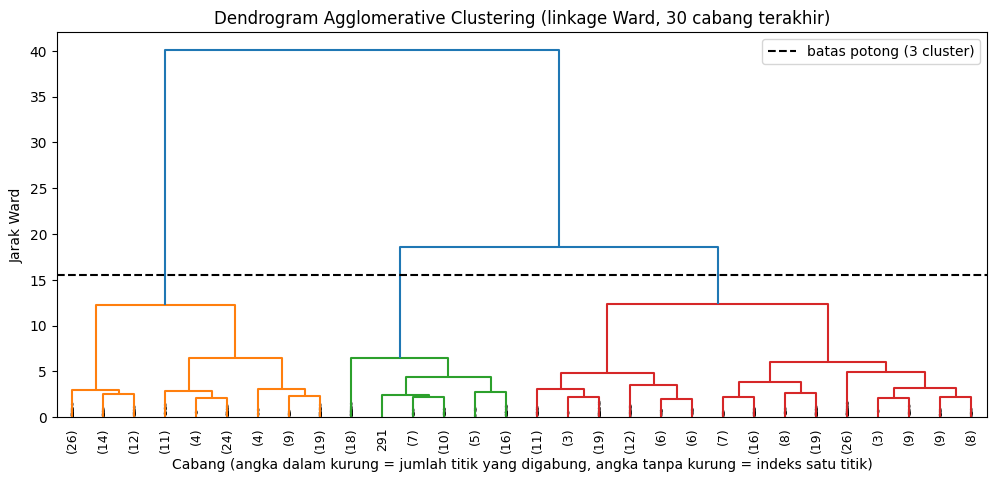

In [13]:
Z = linkage(X_scaled, method="ward")

# garis potong berada di antara tinggi gabungan ke-3 dan ke-2 dari atas, hasilnya 3 cluster
batas_potong = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=batas_potong,
           leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.axhline(batas_potong, color="black", linestyle="--", label="batas potong (3 cluster)")
plt.title("Dendrogram Agglomerative Clustering (linkage Ward, 30 cabang terakhir)")
plt.xlabel("Cabang (angka dalam kurung = jumlah titik yang digabung, angka tanpa kurung = indeks satu titik)")
plt.ylabel("Jarak Ward")
plt.legend()
plt.show()

In [14]:
# Pengecekan konsistensi: potong dendrogram scipy jadi 3 cluster, bandingkan dengan hasil sklearn
label_scipy = fcluster(Z, t=3, criterion="maxclust")
print("ARI antara hasil sklearn dan dendrogram scipy:", adjusted_rand_score(label_agglo, label_scipy))

ARI antara hasil sklearn dan dendrogram scipy: 1.0


Nilai ARI = 1.0 berarti pengelompokan dari `AgglomerativeClustering` identik dengan potongan dendrogram pada 3 cluster, jadi dendrogram di atas memang menggambarkan model yang dipakai.

### 5.B DBSCAN

DBSCAN punya dua parameter utama: `eps` (radius tetangga) dan `min_samples` (jumlah minimal titik dalam radius agar sebuah titik dianggap padat). Konfigurasi utama: `eps = 0.5` dan `min_samples = 5`.

In [15]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
label_dbscan = dbscan.fit_predict(X_scaled)

n_cluster_db = len(set(label_dbscan)) - (1 if -1 in label_dbscan else 0)
n_noise_db = (label_dbscan == -1).sum()

print("Konfigurasi utama: eps = 0.5, min_samples = 5")
print("Jumlah cluster (tanpa noise):", n_cluster_db)
print("Jumlah titik noise (label -1):", n_noise_db)
print()
print("Jumlah anggota per label (-1 = noise):")
pd.Series(label_dbscan).value_counts().sort_index()

Konfigurasi utama: eps = 0.5, min_samples = 5
Jumlah cluster (tanpa noise): 4
Jumlah titik noise (label -1): 69

Jumlah anggota per label (-1 = noise):


-1     69
 0    118
 1    113
 2     15
 3     27
Name: count, dtype: int64

Sekarang saya coba beberapa nilai `eps` lain (dengan `min_samples = 5` tetap) untuk melihat pengaruhnya.

In [16]:
daftar_eps = [0.3, 0.5, 0.7, 0.9, 1.1]
baris_eps = []

for eps in daftar_eps:
    label = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    baris_eps.append({
        "eps": eps,
        "Jumlah cluster": len(set(label)) - (1 if -1 in label else 0),
        "Jumlah noise": int((label == -1).sum()),
    })

tabel_eps = pd.DataFrame(baris_eps)
tabel_eps

,eps,Jumlah cluster,Jumlah noise
0,0.3,4,317
1,0.5,4,69
2,0.7,2,16
3,0.9,2,2
4,1.1,2,1


In [17]:
# Untuk membantu membaca tabel: komposisi spesies pada eps = 0.5 (utama) dan eps = 0.9
for eps in [0.5, 0.9]:
    label = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    print(f"eps = {eps} (baris = label cluster, -1 = noise)")
    print(pd.crosstab(label, y, rownames=["cluster"]), "\n")

eps = 0.5 (baris = label cluster, -1 = noise)
species  Adelie  Chinstrap  Gentoo
cluster                           
-1           36         23      10
 0          115          3       0
 1            0          0     113
 2            0         15       0
 3            0         27       0 

eps = 0.9 (baris = label cluster, -1 = noise)
species  Adelie  Chinstrap  Gentoo
cluster                           
-1            1          1       0
 0          150         67       0
 1            0          0     123 




**Pengaruh perubahan `eps`:**

- `eps = 0.3`: radius terlalu kecil, hampir semua titik (317 dari 342) tidak punya cukup tetangga sehingga jadi noise.
- `eps = 0.5` (konfigurasi utama): terbentuk 4 cluster dan 69 titik noise. Dari tabel silang spesies, cluster 1 hampir seluruhnya Gentoo, cluster 0 didominasi Adelie, dan Chinstrap terpecah menjadi dua cluster kecil (cluster 2 dan 3). Noise-nya berasal dari ketiga spesies, terutama di area yang tumpang tindih.
- `eps = 0.7` sampai `1.1`: radius makin besar, noise turun drastis (16, 2, lalu 1 titik) tetapi cluster hanya tersisa 2. Pada `eps = 0.9`, Adelie dan Chinstrap sudah menyatu jadi satu cluster (150 + 67 titik) dan Gentoo menjadi cluster lain.

Jadi `eps` kecil menghasilkan banyak noise, sedangkan `eps` besar membuat cluster yang berdekatan melebur. Pada data ini DBSCAN tidak pernah menghasilkan tepat 3 cluster untuk nilai `eps` yang dicoba, karena Adelie dan Chinstrap tumpang tindih dan tidak punya "celah" kepadatan yang jelas di antaranya. Sesuai instruksi, `eps = 0.5` tetap dipakai sebagai konfigurasi utama pada perbandingan.


### 5.C Gaussian Mixture Models (GMM)

GMM dengan 3 komponen dan `random_state=42`. Tiap titik dimasukkan ke komponen dengan probabilitas tertinggi. Konfigurasi yang sama dipakai lagi di evaluasi dan uji kestabilan.

In [18]:
gmm = GaussianMixture(n_components=3, random_state=42)
label_gmm = gmm.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster (GMM):")
pd.Series(label_gmm).value_counts().sort_index()

Jumlah anggota tiap cluster (GMM):


0     67
1    123
2    152
Name: count, dtype: int64

### 5.D Spectral Clustering

Saya memakai `affinity="nearest_neighbors"` dengan `n_neighbors=10` (nilai bawaan scikit-learn, jadi tidak disetel berdasarkan label spesies). Dengan affinity ini, tiap titik dihubungkan ke 10 tetangga terdekatnya. Cara ini lebih cocok untuk bentuk data yang tidak bulat sempurna dibanding kernel RBF.

Sebelum menjalankan model, saya cek dulu apakah graf tetangganya terhubung penuh, karena scikit-learn biasanya memberi peringatan jika tidak.

In [19]:
graf_tetangga = kneighbors_graph(X_scaled, n_neighbors=10, include_self=True)
n_komponen, label_komponen = connected_components(graf_tetangga, directed=False)

print("Jumlah komponen terhubung pada graf 10 tetangga:", n_komponen)
print("Ukuran tiap komponen:", np.bincount(label_komponen))

Jumlah komponen terhubung pada graf 10 tetangga: 2
Ukuran tiap komponen: [219 123]


In [20]:
spectral = SpectralClustering(n_clusters=3, affinity="nearest_neighbors",
                              n_neighbors=10, random_state=42)

# peringatan "Graph is not fully connected" sudah dijelaskan di atas, jadi disembunyikan di sini
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    label_spectral = spectral.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster (Spectral Clustering):")
pd.Series(label_spectral).value_counts().sort_index()

Jumlah anggota tiap cluster (Spectral Clustering):


0    162
1    123
2     57
Name: count, dtype: int64


Graf 10 tetangga ternyata terdiri dari 2 komponen terputus (219 dan 123 titik). Ukuran 123 sama dengan jumlah data Gentoo, jadi kemungkinan besar kelompok Gentoo memang terpisah jauh dari dua spesies lainnya sehingga tidak ada satu pun titik yang menjadi tetangga terdekat lintas kelompok. Peringatan scikit-learn itu wajar dan bukan error. Hasilnya tetap 3 cluster dengan ukuran 162, 123, dan 57 titik.


## 6. Visualisasi Hasil Clustering

Clustering dilakukan pada 4 fitur yang sudah distandardisasi, tetapi scatter plot memakai **nilai asli** `flipper_length_mm` (sumbu X) dan `bill_length_mm` (sumbu Y) agar mudah dibaca. Karena hanya dua dari empat dimensi yang digambar, ada cluster yang kelihatan menumpuk di plot padahal terpisah di dimensi lain.

Pertama, sebagai acuan visual, berikut sebaran data berdasarkan spesies asli.

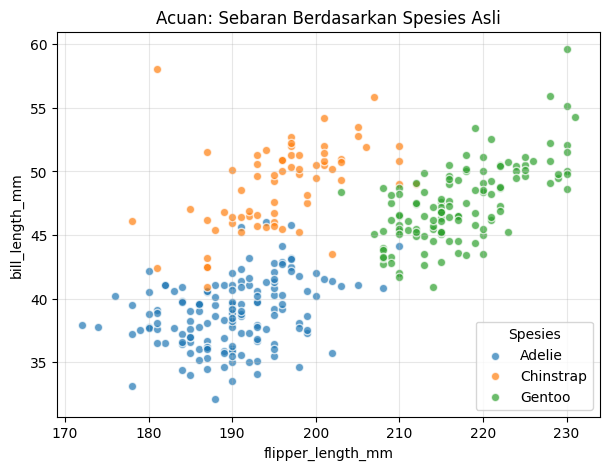

In [21]:
warna = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

plt.figure(figsize=(7, 5))
for sp, warna_sp in zip(["Adelie", "Chinstrap", "Gentoo"], ["tab:blue", "tab:orange", "tab:green"]):
    m = (y == sp).values
    plt.scatter(df_bersih.loc[m, "flipper_length_mm"], df_bersih.loc[m, "bill_length_mm"],
                color=warna_sp, alpha=0.7, edgecolor="white", label=sp)
plt.title("Acuan: Sebaran Berdasarkan Spesies Asli")
plt.xlabel("flipper_length_mm")
plt.ylabel("bill_length_mm")
plt.legend(title="Spesies")
plt.grid(alpha=0.3)
plt.show()

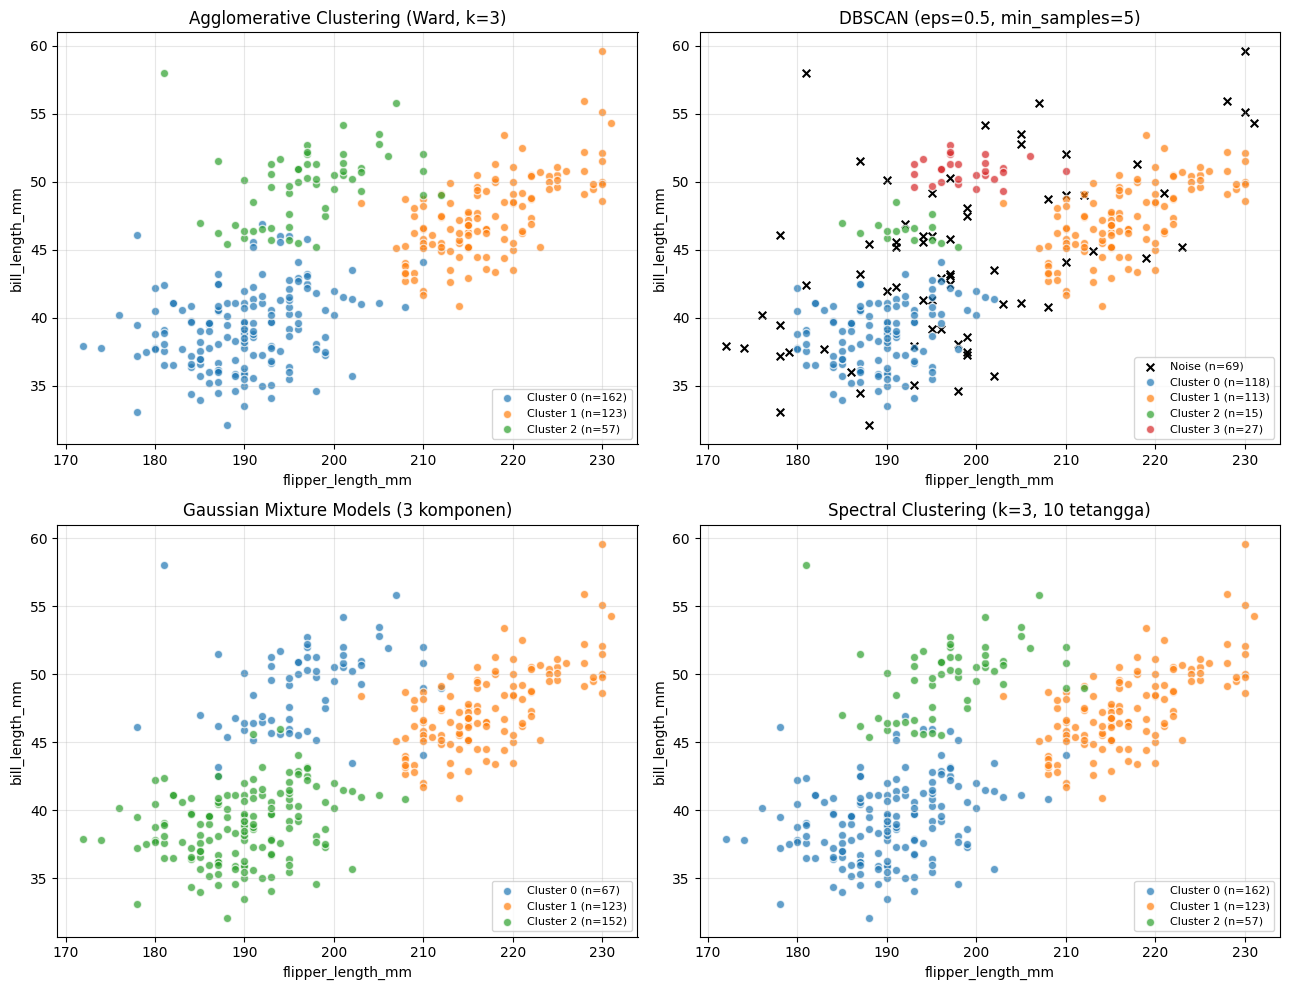

In [22]:
def gambar_cluster(ax, label, judul):
    for k in sorted(set(label)):
        m = label == k
        if k == -1:
            ax.scatter(df_bersih.loc[m, "flipper_length_mm"], df_bersih.loc[m, "bill_length_mm"],
                       color="black", marker="x", s=30, label=f"Noise (n={m.sum()})")
        else:
            ax.scatter(df_bersih.loc[m, "flipper_length_mm"], df_bersih.loc[m, "bill_length_mm"],
                       color=warna[k % len(warna)], alpha=0.7, edgecolor="white",
                       label=f"Cluster {k} (n={m.sum()})")
    ax.set_title(judul)
    ax.set_xlabel("flipper_length_mm")
    ax.set_ylabel("bill_length_mm")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

hasil_label = {
    "Agglomerative": label_agglo,
    "DBSCAN": label_dbscan,
    "GMM": label_gmm,
    "Spectral": label_spectral,
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
gambar_cluster(axes[0, 0], label_agglo, "Agglomerative Clustering (Ward, k=3)")
gambar_cluster(axes[0, 1], label_dbscan, "DBSCAN (eps=0.5, min_samples=5)")
gambar_cluster(axes[1, 0], label_gmm, "Gaussian Mixture Models (3 komponen)")
gambar_cluster(axes[1, 1], label_spectral, "Spectral Clustering (k=3, 10 tetangga)")
plt.tight_layout()
plt.show()

In [23]:
# Tabel silang cluster vs spesies untuk membantu membaca plot (hanya untuk interpretasi, bukan input clustering)
for nama, label in hasil_label.items():
    print(f"{nama} (baris = label cluster, kolom = spesies asli)")
    print(pd.crosstab(label, y, rownames=["cluster"]), "\n")

Agglomerative (baris = label cluster, kolom = spesies asli)
species  Adelie  Chinstrap  Gentoo
cluster                           
0           151         11       0
1             0          0     123
2             0         57       0 

DBSCAN (baris = label cluster, kolom = spesies asli)
species  Adelie  Chinstrap  Gentoo
cluster                           
-1           36         23      10
 0          115          3       0
 1            0          0     113
 2            0         15       0
 3            0         27       0 

GMM (baris = label cluster, kolom = spesies asli)
species  Adelie  Chinstrap  Gentoo
cluster                           
0             2         65       0
1             0          0     123
2           149          3       0 

Spectral (baris = label cluster, kolom = spesies asli)
species  Adelie  Chinstrap  Gentoo
cluster                           
0           151         11       0
1             0          0     123
2             0         57       0 




**Hal yang terlihat dari plot dan tabel silang:**

- Gentoo (sirip panjang, kanan atas) terpisah jelas. Agglomerative, GMM, dan Spectral semuanya menghasilkan satu cluster berisi tepat 123 titik Gentoo. DBSCAN menghasilkan cluster Gentoo 113 titik, sedangkan 10 titik Gentoo lainnya masuk noise.
- Bagian yang sulit adalah Adelie vs Chinstrap karena sebarannya tumpang tindih.
- Agglomerative dan Spectral menghasilkan pengelompokan yang sama persis ukurannya (162, 123, 57). Chinstrap yang bagian bawahnya menumpuk dengan Adelie (11 titik) ikut masuk cluster Adelie.
- GMM paling mendekati spesies asli (cluster 0 berisi 65 Chinstrap dan 2 Adelie, cluster 2 berisi 149 Adelie dan 3 Chinstrap). Bentuk cluster GMM elips, jadi lebih fleksibel menangkap sebaran Adelie dan Chinstrap yang miring.
- DBSCAN memecah Chinstrap jadi dua cluster kecil dan membuang 69 titik sebagai noise.


## 7. Evaluasi Hasil Clustering

Tiga metrik yang dipakai:

- **Silhouette Score** (internal, -1 sampai 1): seberapa dekat titik dengan clusternya sendiri dibanding cluster lain. Makin tinggi makin baik. Dihitung pada data yang distandardisasi. Untuk DBSCAN, titik noise tidak diikutkan, dan skor hanya dihitung jika ada minimal 2 cluster non-noise.
- **Rand Index** (eksternal, 0 sampai 1): proporsi pasangan titik yang "sepakat" antara hasil clustering dan label spesies (sama-sama satu kelompok atau sama-sama beda kelompok).
- **NMI** (eksternal, 0 sampai 1): seberapa banyak informasi label spesies yang tertangkap oleh hasil clustering.

Untuk Rand Index dan NMI, seluruh 342 data dipakai. Pada DBSCAN, noise (label -1) diperlakukan sebagai satu label cluster tersendiri. Artinya, noise dihitung sebagai "satu kelompok" sehingga titik noise yang berasal dari spesies berbeda tetap dianggap sekelompok, dan ini ikut menurunkan skor DBSCAN.

In [24]:
baris_eval = []
keterangan = []

for nama, label in hasil_label.items():
    # Silhouette: buang noise (label -1) dan butuh minimal 2 cluster tersisa
    bukan_noise = label != -1
    n_dibuang = int((~bukan_noise).sum())
    n_cluster_valid = len(set(label[bukan_noise]))

    if n_cluster_valid >= 2:
        sil = silhouette_score(X_scaled[bukan_noise], label[bukan_noise])
    else:
        sil = np.nan
        keterangan.append(f"{nama}: Silhouette tidak dapat dihitung (cluster non-noise kurang dari 2).")

    if n_dibuang > 0:
        keterangan.append(f"{nama}: {n_dibuang} titik noise dikeluarkan dari perhitungan Silhouette.")

    baris_eval.append({
        "Algoritma": nama,
        "Jumlah Cluster": n_cluster_valid,
        "Titik Noise": n_dibuang,
        "Silhouette Score": sil,
        "Rand Index": rand_score(y, label),
        "NMI": normalized_mutual_info_score(y, label),
    })

tabel_eval = pd.DataFrame(baris_eval)
for k in keterangan:
    print(k)
tabel_eval.round(4)

DBSCAN: 69 titik noise dikeluarkan dari perhitungan Silhouette.


,Algoritma,Jumlah Cluster,Titik Noise,Silhouette Score,Rand Index,NMI
0,Agglomerative,3,0,0.4541,0.9608,0.9007
1,DBSCAN,4,69,0.4235,0.8525,0.6631
2,GMM,3,0,0.4545,0.9817,0.9349
3,Spectral,3,0,0.4550,0.9608,0.9007


## 8. Uji Kestabilan Clustering

Untuk menguji kestabilan, tiap algoritma dijalankan ulang pada **90% data yang diambil acak tanpa pengembalian**, sebanyak **3 kali**. Hasil pada subset dibandingkan dengan hasil pada data penuh, hanya pada baris yang sama (indeks subset), memakai **Adjusted Rand Index (ARI)**. ARI cocok di sini karena membandingkan dua pengelompokan tanpa terpengaruh perbedaan penomoran label cluster. Nilai 1 berarti pengelompokan identik, nilai mendekati 0 berarti mirip acak.

Catatan: subset diambil dari `X_scaled` yang sudah distandardisasi pada data penuh, jadi skala fitur dan parameter seperti `eps` tetap sama. Seed pengambilan subset dikunci (`RandomState(42)`) dan subset yang sama dipakai untuk keempat algoritma. Standar deviasi yang dilaporkan adalah standar deviasi sampel (`ddof=1`). DBSCAN memperlakukan noise sebagai label -1.

In [25]:
# Konfigurasi sama persis dengan yang dipakai pada data penuh
model_stabilitas = {
    "Agglomerative": lambda: AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "DBSCAN":        lambda: DBSCAN(eps=0.5, min_samples=5),
    "GMM":           lambda: GaussianMixture(n_components=3, random_state=42),
    "Spectral":      lambda: SpectralClustering(n_clusters=3, affinity="nearest_neighbors",
                                                n_neighbors=10, random_state=42),
}

# Pengecekan: konfigurasi di atas pada data penuh harus menghasilkan label yang sama dengan sebelumnya
for nama, buat_model in model_stabilitas.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ulang = buat_model().fit_predict(X_scaled)
    print(f"{nama:14s} ARI terhadap hasil sebelumnya = {adjusted_rand_score(hasil_label[nama], ulang):.4f}")

Agglomerative  ARI terhadap hasil sebelumnya = 1.0000
DBSCAN         ARI terhadap hasil sebelumnya = 1.0000
GMM            ARI terhadap hasil sebelumnya = 1.0000
Spectral       ARI terhadap hasil sebelumnya = 1.0000


In [26]:
n_data = len(X_scaled)
n_subset = int(round(0.9 * n_data))
rng = np.random.RandomState(42)

# tiga subset acak 90% tanpa pengembalian (indeks diurutkan agar urutan baris tetap)
daftar_indeks = [np.sort(rng.choice(n_data, size=n_subset, replace=False)) for _ in range(3)]
print("Jumlah data penuh:", n_data, "| jumlah data per subset (90%):", n_subset)

hasil_ari = {}
for nama, buat_model in model_stabilitas.items():
    daftar_ari = []
    for idx in daftar_indeks:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            label_subset = buat_model().fit_predict(X_scaled[idx])
        label_penuh_sama_baris = hasil_label[nama][idx]       # baris yang sama
        daftar_ari.append(adjusted_rand_score(label_penuh_sama_baris, label_subset))
    hasil_ari[nama] = daftar_ari

tabel_stabilitas = pd.DataFrame(hasil_ari, index=["ARI Percobaan 1", "ARI Percobaan 2", "ARI Percobaan 3"]).T
tabel_stabilitas["Rata-rata"] = tabel_stabilitas.mean(axis=1)
tabel_stabilitas["Standar Deviasi"] = tabel_stabilitas[["ARI Percobaan 1", "ARI Percobaan 2", "ARI Percobaan 3"]].std(axis=1, ddof=1)
tabel_stabilitas.round(4)

Jumlah data penuh: 342 | jumlah data per subset (90%): 308


,ARI Percobaan 1,ARI Percobaan 2,ARI Percobaan 3,Rata-rata,Standar Deviasi
Agglomerative,0.6467,0.7047,0.9318,0.7610,0.1507
DBSCAN,0.9216,0.9566,0.8841,0.9208,0.0363
GMM,0.9910,0.8235,1.0000,0.9382,0.0994
Spectral,0.9912,1.0000,1.0000,0.9971,0.0051


In [27]:
# Diagnosis GMM pada percobaan ke-2 (hanya untuk memahami penyebab ARI yang lebih rendah)
idx2 = daftar_indeks[1]
label_gmm_sub2 = GaussianMixture(n_components=3, random_state=42).fit_predict(X_scaled[idx2])

print("Label GMM data penuh (baris) vs label GMM subset (kolom), percobaan ke-2, baris yang sama:")
print(pd.crosstab(label_gmm[idx2], label_gmm_sub2, rownames=["penuh"], colnames=["subset"]))

print()
print("Mencoba beberapa random_state lain pada subset yang sama (hanya diagnosis, konfigurasi utama tetap 42):")
for rs in range(5):
    g = GaussianMixture(n_components=3, random_state=rs).fit(X_scaled[idx2])
    ari = adjusted_rand_score(label_gmm[idx2], g.predict(X_scaled[idx2]))
    print(f"random_state={rs}: log-likelihood per titik = {g.lower_bound_:.4f}, ARI = {ari:.4f}")

Label GMM data penuh (baris) vs label GMM subset (kolom), percobaan ke-2, baris yang sama:
subset    0    1   2
penuh               
0         0    0  59
1         0  113   0
2       114    0  22

Mencoba beberapa random_state lain pada subset yang sama (hanya diagnosis, konfigurasi utama tetap 42):
random_state=0: log-likelihood per titik = -3.3558, ARI = 0.8235
random_state=1: log-likelihood per titik = -3.3558, ARI = 0.8235
random_state=2: log-likelihood per titik = -3.3558, ARI = 0.8235
random_state=3: log-likelihood per titik = -3.3288, ARI = 1.0000
random_state=4: log-likelihood per titik = -3.3558, ARI = 0.8235



**Pembacaan hasil kestabilan:**

- **Spectral** paling stabil (rata-rata ARI sekitar 0.997, standar deviasi sekitar 0.005). Pengelompokannya hampir tidak berubah walau 10% data dibuang.
- **DBSCAN** cukup stabil (rata-rata sekitar 0.921, standar deviasi sekitar 0.036). Hasilnya bergeser sedikit karena kepadatan lokal ikut berubah saat sebagian titik hilang, terutama pada titik noise di area tumpang tindih.
- **GMM** rata-ratanya sekitar 0.938, tetapi standar deviasinya cukup besar (sekitar 0.099) karena satu percobaan (percobaan 2) turun ke 0.82, sementara dua percobaan lain 0.99 sampai 1.00. Dari sel diagnosis, pada subset itu `random_state=42` menghasilkan solusi di mana 22 titik yang pada data penuh masuk cluster Adelie (cluster 2) berpindah ke cluster Chinstrap (cluster 0 pada data penuh). Dari 5 `random_state` yang dicoba, satu menghasilkan log-likelihood lebih tinggi dan ARI 1.0. Jadi penyebabnya adalah GMM bergantung pada titik awal inisialisasi EM dan bisa berhenti di solusi lokal yang kurang optimal, bukan karena pemodelannya salah.
- **Agglomerative (Ward)** paling tidak stabil (rata-rata sekitar 0.761, standar deviasi sekitar 0.151). Kemungkinan besar karena batas Adelie dan Chinstrap yang tumpang tindih membuat urutan penggabungan dan potongan 3 cluster mudah bergeser ketika sebagian data hilang.

Catatan: uji ini hanya 3 kali pengulangan, jadi standar deviasinya hanya gambaran kasar, bukan estimasi yang kuat.


## 9. Tabel Perbandingan Akhir

Seluruh angka di tabel ini diambil langsung dari variabel hasil perhitungan sebelumnya (`tabel_eval` dan `tabel_stabilitas`), tidak ditulis manual.

In [28]:
tabel_akhir = pd.DataFrame({
    "Algoritma": tabel_eval["Algoritma"],
    "Jumlah Cluster": tabel_eval["Jumlah Cluster"],
    "Silhouette Score": tabel_eval["Silhouette Score"],
    "Rand Index": tabel_eval["Rand Index"],
    "NMI": tabel_eval["NMI"],
    "Rata-rata ARI Stability": tabel_stabilitas["Rata-rata"].values,
    "Standar Deviasi Stability": tabel_stabilitas["Standar Deviasi"].values,
})

n_noise_db_akhir = int(tabel_eval.loc[tabel_eval["Algoritma"] == "DBSCAN", "Titik Noise"].iloc[0])
print("Keterangan:")
print(f"- Jumlah cluster DBSCAN tidak menghitung noise. Noise ({n_noise_db_akhir} titik) dikeluarkan dari Silhouette Score,")
print("  tetapi diperlakukan sebagai label -1 pada Rand Index, NMI, dan uji kestabilan.")
print("- Seluruh nilai pada tabel berhasil dihitung (tidak ada yang kosong).")
print()
tabel_akhir.round(4).reset_index(drop=True)

Keterangan:
- Jumlah cluster DBSCAN tidak menghitung noise. Noise (69 titik) dikeluarkan dari Silhouette Score,
  tetapi diperlakukan sebagai label -1 pada Rand Index, NMI, dan uji kestabilan.
- Seluruh nilai pada tabel berhasil dihitung (tidak ada yang kosong).



,Algoritma,Jumlah Cluster,Silhouette Score,Rand Index,NMI,Rata-rata ARI Stability,Standar Deviasi Stability
0,Agglomerative,3,0.4541,0.9608,0.9007,0.7610,0.1507
1,DBSCAN,4,0.4235,0.8525,0.6631,0.9208,0.0363
2,GMM,3,0.4545,0.9817,0.9349,0.9382,0.0994
3,Spectral,3,0.4550,0.9608,0.9007,0.9971,0.0051


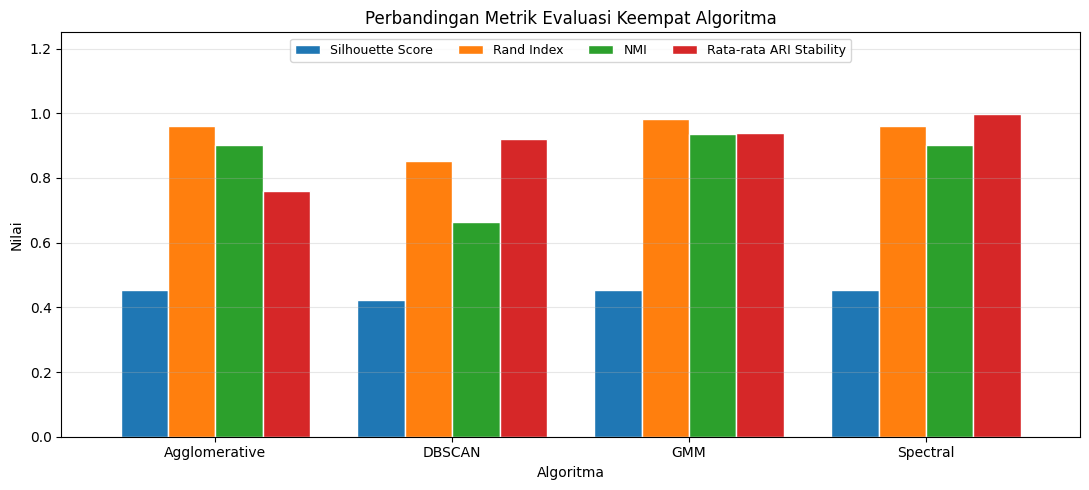

In [29]:
# Visualisasi ringkas perbandingan metrik
metrik = ["Silhouette Score", "Rand Index", "NMI", "Rata-rata ARI Stability"]
tabel_plot = tabel_akhir.set_index("Algoritma")[metrik]

ax = tabel_plot.plot(kind="bar", figsize=(11, 5), width=0.8, edgecolor="white")
ax.set_title("Perbandingan Metrik Evaluasi Keempat Algoritma")
ax.set_ylabel("Nilai")
ax.set_ylim(0, 1.25)
ax.set_xticklabels(tabel_plot.index, rotation=0)
ax.legend(loc="upper center", ncol=4, fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Kesimpulan

**Ringkasan hasil keempat algoritma.** Pada data Palmer Penguins yang sudah dibersihkan (342 baris) dan distandardisasi, ketiga algoritma dengan jumlah cluster 3 (Agglomerative, GMM, Spectral) berhasil memisahkan Gentoo dengan sangat baik. Perbedaan utamanya ada pada pemisahan Adelie dan Chinstrap yang tumpang tindih. DBSCAN dengan `eps = 0.5` menghasilkan 4 cluster dan 69 titik noise.

**Algoritma terbaik: GMM**, dengan pertimbangan seluruh metrik (bukan satu metrik saja):

- **Silhouette Score**: keempat algoritma berdekatan (sekitar 0.42 sampai 0.455), jadi metrik ini tidak banyak membedakan. Nilai DBSCAN paling rendah, dan itu pun dihitung tanpa 69 titik noise.
- **Rand Index dan NMI**: GMM tertinggi (sekitar 0.982 dan 0.935). Agglomerative dan Spectral sama (sekitar 0.961 dan 0.901), DBSCAN terendah (sekitar 0.853 dan 0.663). Skor DBSCAN ikut turun karena noise dihitung sebagai satu label tersendiri.
- **Kestabilan**: Spectral paling stabil (sekitar 0.997), disusul GMM (sekitar 0.938), DBSCAN (sekitar 0.921), lalu Agglomerative (sekitar 0.761). Penurunan GMM berasal dari satu percobaan yang inisialisasinya kurang beruntung, sedangkan dua percobaan lainnya hampir sempurna.

GMM dipilih karena paling sesuai dengan pengelompokan spesies pada RI dan NMI, dengan silhouette setara yang terbaik, dan kestabilannya masih baik. **Spectral Clustering adalah alternatif yang kuat** jika kestabilan jadi prioritas utama, karena kualitasnya hanya sedikit di bawah GMM dan hasilnya paling konsisten.

**Kelebihan dan kekurangan berdasarkan eksperimen:**

| Algoritma | Kelebihan | Kekurangan |
|---|---|---|
| Agglomerative (Ward) | Ada dendrogram yang membantu melihat struktur penggabungan; hasil deterministik pada data penuh. | Paling tidak stabil saat data dikurangi; 11 titik Chinstrap salah masuk ke cluster Adelie. |
| DBSCAN | Tidak perlu menentukan jumlah cluster; bisa mengenali titik yang janggal sebagai noise. | Sangat sensitif terhadap `eps` (4 cluster dengan 69 noise pada 0.5, tinggal 2 cluster pada 0.7 ke atas); gagal memisahkan Adelie dan Chinstrap yang tumpang tindih. |
| GMM | Cluster berbentuk elips sehingga cocok dengan sebaran data ini; skor RI dan NMI tertinggi. | Perlu menentukan jumlah komponen di awal; hasil bergantung pada inisialisasi (terlihat pada percobaan 2 uji kestabilan). |
| Spectral | Hasil paling stabil; kualitas mendekati GMM. | Perlu menentukan jumlah cluster dan jumlah tetangga; graf tetangga terputus (muncul peringatan); komputasi lebih berat untuk data besar. |

**Catatan.** Rand Index dan NMI memakai `species` sebagai acuan, padahal spesies bukan satu-satunya cara yang valid untuk mengelompokkan data. Selain itu GMM, Agglomerative, dan Spectral diberi tahu jumlah cluster = 3 dari awal, sedangkan DBSCAN tidak, sehingga perbandingannya tidak sepenuhnya setara. Uji kestabilan juga hanya memakai 3 pengulangan, jadi kesimpulan stabilitas sebaiknya dibaca sebagai indikasi, bukan angka pasti.
